# Nanoguide with 14 MeV neutrons: track lengths and directions

**Tsviki Y. Hirsh** · 4 November 2026

The nanoguide of `ambe_tracks_overview.ipynb` (EJ-200-type fibres in PMMA, 10 mm × 10 mm ×
100 mm, viewed end-on) with 14 MeV neutrons from a point source 50 mm away, in two
directions: **side-on** (perpendicular to the fibres, at azimuth 0°, like the AmBe study)
and **along the fibres** (into the far end). Tracks are the light of one interaction on the
end face, with at least 20 photons; lengths are projected on the end face (the 2nd–98th
percentile extent of the photons along the track axis), as the camera would see them with
all photons. AmBe tracks from `ambe_azimuth_scan.ipynb` are shown for reference.

In [1]:
import os, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

REPO = Path.cwd().resolve().parents[1]          # this notebook lives in <G4LumaCam>/notebooks/nanoguide
sys.path.insert(0, str(REPO / "src"))
import lumacam

EXE = REPO / "build" / "lumacam"
ARCHIVE = Path("archive")
N_NEUTRONS, JOBS = 150_000, 8                   # per beam direction
MIN_PHOTONS, PROMPT_NS = 20, 100.0
PIXEL_MM = 10.0 / 256

INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {"n, 1st interaction: proton": "#2a78d6", "n, 1st interaction: alpha": "#1baf7a",
          "n, later interaction": "#eb6834", "γ": "#eda100"}
BLUES = LinearSegmentedColormap.from_list("blues", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6,
})

## Simulations

Eight parallel runs per beam direction, cached in `archive/dt14/` (about 5 minutes on 16 cores).

In [2]:
def config(direction):
    c = lumacam.Config.ambe_nanoguide(azimuth=0, distance=50, particle="neutron",
                                      spectrum=[(13.95, 1.0), (14.05, 1.0)], num_events=N_NEUTRONS // JOBS)
    if direction == "axial":   # point source 50 mm before the far end, beam along the fibres
        c.position_x, c.position_y, c.position_z = 0, 0, -50
        c.min_phi = c.max_phi = None
        c.min_theta, c.max_theta = 171.5, 180.0
    return c

def simulate(direction, j):
    d = ARCHIVE / "dt14" / direction / f"part{j}"
    if (d / "done").exists():
        return
    d.mkdir(parents=True, exist_ok=True)
    config(direction).write(str(d / "body.mac"))
    (d / "macro.mac").write_text(f"/random/setSeeds {7000 + 100 * j + (direction == 'axial')} {9100 + j}\n"
                                 + (d / "body.mac").read_text())
    with open(d / "log.txt", "w") as log:
        subprocess.run([str(EXE), "macro.mac"], cwd=d, stdout=log, stderr=subprocess.STDOUT, check=True)
    (d / "done").write_text("")

with ThreadPoolExecutor(os.cpu_count()) as pool:
    list(pool.map(lambda a: simulate(*a), [(g, j) for g in ("side", "axial") for j in range(JOBS)]))

## Tracks

Every interaction with at least 20 prompt photons on the end face is one track: its
projected length, its direction (from the vertex of its brightest emitting particle to the
light centroid, as in `ambe_tracks_overview.ipynb`), and what it is: the proton or alpha
from the neutron's first interaction, a later interaction, or the electron of a gamma
(made in the guide by the neutrons, or the 4.44 MeV gamma of the AmBe source).

In [3]:
def tracks(files):
    out = []
    for f in files:
        df = pd.read_csv(f, usecols=["neutron_id", "n_int", "parent_id", "x", "y", "px", "py",
                                     "toa", "pulse_time_ns", "parentName"])
        df = df[(df.toa - df.pulse_time_ns) < PROMPT_NS]
        df["g"] = df.neutron_id.astype(np.int64) * 100 + df.n_int
        df = df[df.groupby("g").x.transform("size") >= MIN_PHOTONS].copy()
        if df.empty:
            continue
        g = df.groupby("g")
        dx, dy = df.x - g.x.transform("mean"), df.y - g.y.transform("mean")
        sxx, syy = (dx * dx).groupby(df.g).transform("mean"), (dy * dy).groupby(df.g).transform("mean")
        sxy = (dx * dy).groupby(df.g).transform("mean")
        axis = 0.5 * np.arctan2(2 * sxy, sxx - syy)                       # principal axis
        df["proj"] = dx * np.cos(axis) + dy * np.sin(axis)
        q = df.groupby("g").proj.quantile([0.02, 0.98]).unstack()
        lead = (df.groupby(["g", "parent_id"]).agg(n=("x", "size"), particle=("parentName", "first"),
                                                   px=("px", "first"), py=("py", "first"))
                  .reset_index().sort_values("n").drop_duplicates("g", keep="last").set_index("g"))
        t = pd.DataFrame({"length": q[0.98] - q[0.02], "photons": g.size(), "n_int": g.n_int.first(),
                          "x": g.x.mean(), "y": g.y.mean(), "neutron_id": g.neutron_id.first()})
        t = t.join(lead[["particle", "px", "py"]])
        t["file"] = str(f)
        out.append(t)
    return pd.concat(out)

def kind(t, gamma_source=False):
    e = t.particle.isin(["e-", "e+"])
    return np.select([np.full(len(t), gamma_source) | e, t.n_int > 1, t.particle == "proton", t.particle == "alpha"],
                     ["γ", "n, later interaction", "n, 1st interaction: proton", "n, 1st interaction: alpha"],
                     default="n, 1st interaction: other")

cache = ARCHIVE / "dt14" / "tracks.csv.gz"
if cache.exists():
    T = pd.read_csv(cache)
else:
    parts = []
    for name, pattern, gs in [("14 MeV, side-on", "dt14/side/part*/SimPhotons/sim_data_*.csv", False),
                              ("14 MeV, along the fibres", "dt14/axial/part*/SimPhotons/sim_data_*.csv", False),
                              ("AmBe", "neutron_az000/SimPhotons/sim_data_*.csv", False),
                              ("AmBe", "gamma_az000/SimPhotons/sim_data_*.csv", True)]:
        t = tracks(sorted(ARCHIVE.glob(pattern)))
        parts.append(t.assign(source=name, kind=kind(t, gs)))
    T = pd.concat(parts).reset_index()
    T.to_csv(cache, index=False)
T["theta"] = np.degrees(np.arctan2(T.y - T.py, T.x - T.px)) % 360

summary = (T.groupby(["source", "kind"]).length
            .agg(tracks="size", mean_mm="mean", median_mm="median", p90_mm=lambda s: s.quantile(0.9)))
summary[summary.tracks >= 20].round(3)

tracks  mean_mm  \
source                   kind                                          
14 MeV, along the fibres n, 1st interaction: alpha      275    0.037   
                         n, 1st interaction: proton    7599    0.340   
                         n, later interaction           884    0.395   
                         γ                              268    2.959   
14 MeV, side-on          n, 1st interaction: alpha      112    0.039   
                         n, 1st interaction: proton    3390    0.599   
                         n, later interaction           254    0.446   
                         γ                              127    2.491   
AmBe                     n, 1st interaction: proton    7865    0.092   
                         n, later interaction           789    0.068   
                         γ                             2579    3.914   

                                                     median_mm  p90_mm  
source                   kind                                           
14 MeV, along the fibres n, 1st interaction: alpha       0.040   0.059  
                         n, 1st interaction: proton      0.354   0.576  
                         n, later interaction            0.178   0.712  
                         γ                               2.143   7.028  
14 MeV, side-on          n, 1st interaction: alpha       0.033   0.077  
                         n, 1st interaction: proton      0.443   1.414  
                         n, later interaction            0.135   0.956  
                         γ                               1.629   5.756  
AmBe                     n, 1st interaction: proton      0.057   0.213  
                         n, later interaction            0.033   0.115  
                         γ                               3.588   7.685

## Track lengths

At 14 MeV the recoil protons run up to about 2 mm in plastic, so their tracks are several
times longer than at AmBe energies, but still shorter than the electron tracks of gammas.
A beam along the fibres throws the recoils mostly along the guide, so less of their length
shows on the end face.

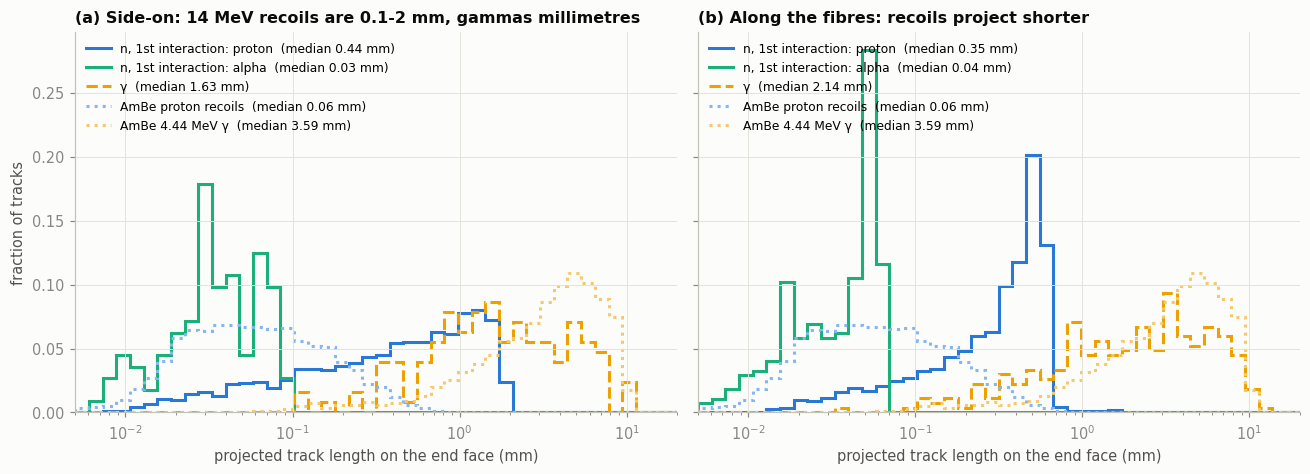

In [4]:
bins = np.logspace(np.log10(0.005), np.log10(20), 45)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, src in zip(axes, ["14 MeV, side-on", "14 MeV, along the fibres"]):
    for k, color in COLORS.items():
        s = T[(T.source == src) & (T.kind == k)].length
        if len(s) >= 20 and k != "n, later interaction":
            ax.stairs(np.histogram(s, bins)[0] / len(s), bins, color=color, ls="--" if k == "γ" else "-",
                      lw=2, label=f"{k}  (median {s.median():.2f} mm)")
    for k, color, lab in [("n, 1st interaction: proton", "#86b6ef", "AmBe proton recoils"),
                          ("γ", "#f5c86b", "AmBe 4.44 MeV γ")]:
        s = T[(T.source == "AmBe") & (T.kind == k)].length
        ax.stairs(np.histogram(s, bins)[0] / len(s), bins, color=color, ls=":", lw=2,
                  label=f"{lab}  (median {s.median():.2f} mm)")
    ax.set_xscale("log"); ax.set_xlim(bins[0], bins[-1])
    ax.set_xlabel("projected track length on the end face (mm)")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("fraction of tracks")
axes[0].set_title("(a) Side-on: 14 MeV recoils are 0.1-2 mm, gammas millimetres", loc="left")
axes[1].set_title("(b) Along the fibres: recoils project shorter", loc="left")
fig.tight_layout()
plt.show()

## What 14 MeV events look like

Every photon on the end face of four simulated tracks, binned in microscope pixels
(39 µm), each in a window sized to the track.

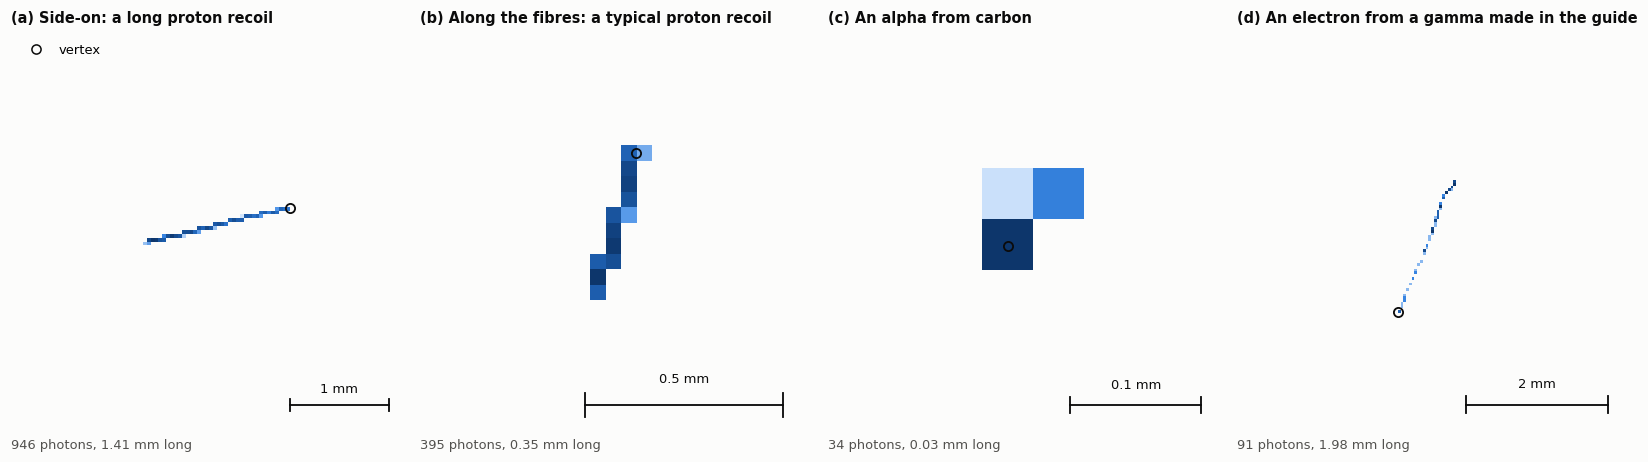

In [5]:
def photons_of(t):
    df = pd.read_csv(t.file)
    return df[(df.neutron_id == t.neutron_id) & (df.n_int == t.n_int)]

def scale_bar(ax, x0, y0, length, label):
    ax.plot([x0, x0 + length], [y0, y0], color=INK, lw=1.2)
    for x in (x0, x0 + length):
        ax.plot([x, x], [y0 - length * 0.06, y0 + length * 0.06], color=INK, lw=1.2)
    ax.text(x0 + length / 2, y0 + length * 0.1, label, ha="center", va="bottom", fontsize=8.5, color=INK)

def near(sel, value):
    # the track whose length is closest to value (a typical example, not an extreme)
    return sel.iloc[(sel.length - value).abs().argsort().iloc[0]]

side, axial = T[T.source == "14 MeV, side-on"], T[T.source == "14 MeV, along the fibres"]
p_side = side[side.kind == "n, 1st interaction: proton"]
p_axial = axial[axial.kind == "n, 1st interaction: proton"]
alpha = side[side.kind == "n, 1st interaction: alpha"]
gamma = pd.concat([side, axial])[lambda d: d.kind == "γ"]
examples = [(near(p_side, p_side.length.quantile(0.9)), "(a) Side-on: a long proton recoil", 1.0),
            (near(p_axial, p_axial.length.median()), "(b) Along the fibres: a typical proton recoil", 1.0),
            (near(alpha, alpha.length.median()), "(c) An alpha from carbon", 0.2),
            (near(gamma, gamma.length.median()), "(d) An electron from a gamma made in the guide", 2.0)]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, (t, title, bar) in zip(axes, examples):
    ph = photons_of(t)
    cx, cy = ph.x.mean(), ph.y.mean()
    w = max(1.4 * t.length, 0.15)
    e = np.arange(-w, w + 1e-9, PIXEL_MM)
    h = np.histogram2d(ph.x - cx, ph.y - cy, [e, e])[0]
    ax.imshow(np.where(h > 0, np.log1p(h), np.nan).T, origin="lower", extent=[e[0], e[-1], e[0], e[-1]],
              cmap=BLUES, vmin=0, interpolation="nearest")
    ax.plot(t.px - cx, t.py - cy, "o", ms=6, mfc="none", mec=INK, mew=1.2)
    ax.set_xlim(-w, w); ax.set_ylim(-w, w); ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.text(-w, -w * 1.12, f"{len(ph)} photons, {t.length:.2f} mm long", color=INK2, fontsize=8.5)
    bar = min(bar, round(w, 1))
    scale_bar(ax, w - bar * 1.15, -w * 0.9, bar, f"{bar:g} mm")
axes[0].plot([], [], "o", mfc="none", mec=INK, label="vertex"); axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

## Track directions

The track angle θ (vertex to light centroid, from +x) for each track type, normalised to
its own total (alpha tracks, about 0.03 mm, are too short for a direction). Side-on, with
the source at 0°, the proton recoils of the first interaction point away from the source;
gammas made in the guide fly off in all directions, and so do their electrons. Along the
fibres, no direction in the end face is preferred.

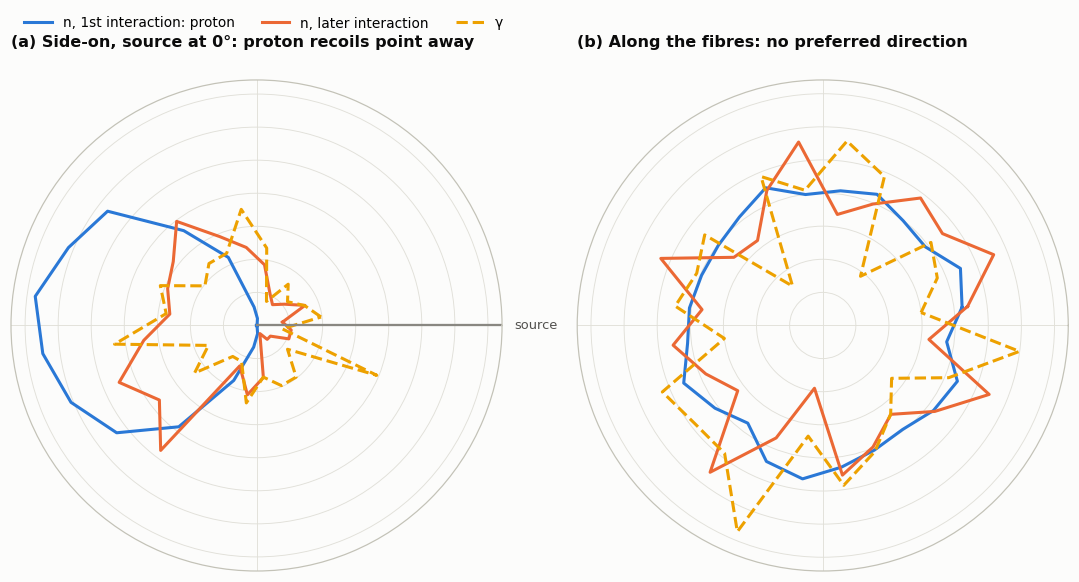

In [6]:
edges = np.arange(0, 361, 15)
centres = np.radians(np.r_[edges[:-1] + 7.5, 7.5])
fig, axes = plt.subplots(1, 2, figsize=(10, 5), subplot_kw={"projection": "polar"})
for ax, src, title in [(axes[0], "14 MeV, side-on", "(a) Side-on, source at 0°: proton recoils point away"),
                       (axes[1], "14 MeV, along the fibres", "(b) Along the fibres: no preferred direction")]:
    top = 0
    for k, color in COLORS.items():
        th = T[(T.source == src) & (T.kind == k) & (T.length > 0.05)].theta
        if k == "n, 1st interaction: alpha":
            continue
        h = np.histogram(th, edges)[0] / len(th)
        ax.plot(centres, np.r_[h, h[0]], color=color, lw=2, ls="--" if k == "γ" else "-", label=k)
        top = max(top, h.max())
    ax.set_ylim(0, top * 1.1)
    if src.endswith("side-on"):
        ax.plot([0, 0], [0, top * 1.1], color=MUTED, lw=1.5)
        ax.text(0, top * 1.25, "source", color=INK2, ha="center", va="center", fontsize=8.5)
    ax.set_yticklabels([]); ax.set_xticks(np.radians(range(0, 360, 90))); ax.set_xticklabels([])
    ax.grid(color=GRID)
    ax.set_title(title, loc="left", pad=22)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper left", bbox_to_anchor=(0.02, 1.06), fontsize=9)
fig.tight_layout()
plt.show()